<a href="https://colab.research.google.com/github/farah-naz01/MRI-Physics-and-Reconstruction/blob/main/01_Bloch_Equation_Simulation/Bloch_Equation_Simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("MRI Physics and Reconstruction")
print("NumPy version:", np.__version__)
print("Google Colab is ready!")

MRI Physics and Reconstruction
NumPy version: 2.4.6
Google Colab is ready!


In [2]:
!git clone https://github.com/farah-naz01/MRI-Physics-and-Reconstruction.git

Cloning into 'MRI-Physics-and-Reconstruction'...
remote: Enumerating objects: 21, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 21 (delta 1), reused 6 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (21/21), 80.06 KiB | 4.45 MiB/s, done.
Resolving deltas: 100% (1/1), done.


In [3]:
%cd /content/MRI-Physics-and-Reconstruction

!python 01_Bloch_Equation_Simulation/bloch_simulation.py

/content/MRI-Physics-and-Reconstruction
Saved 01_Bloch_Equation_Simulation/figures/relaxation.png


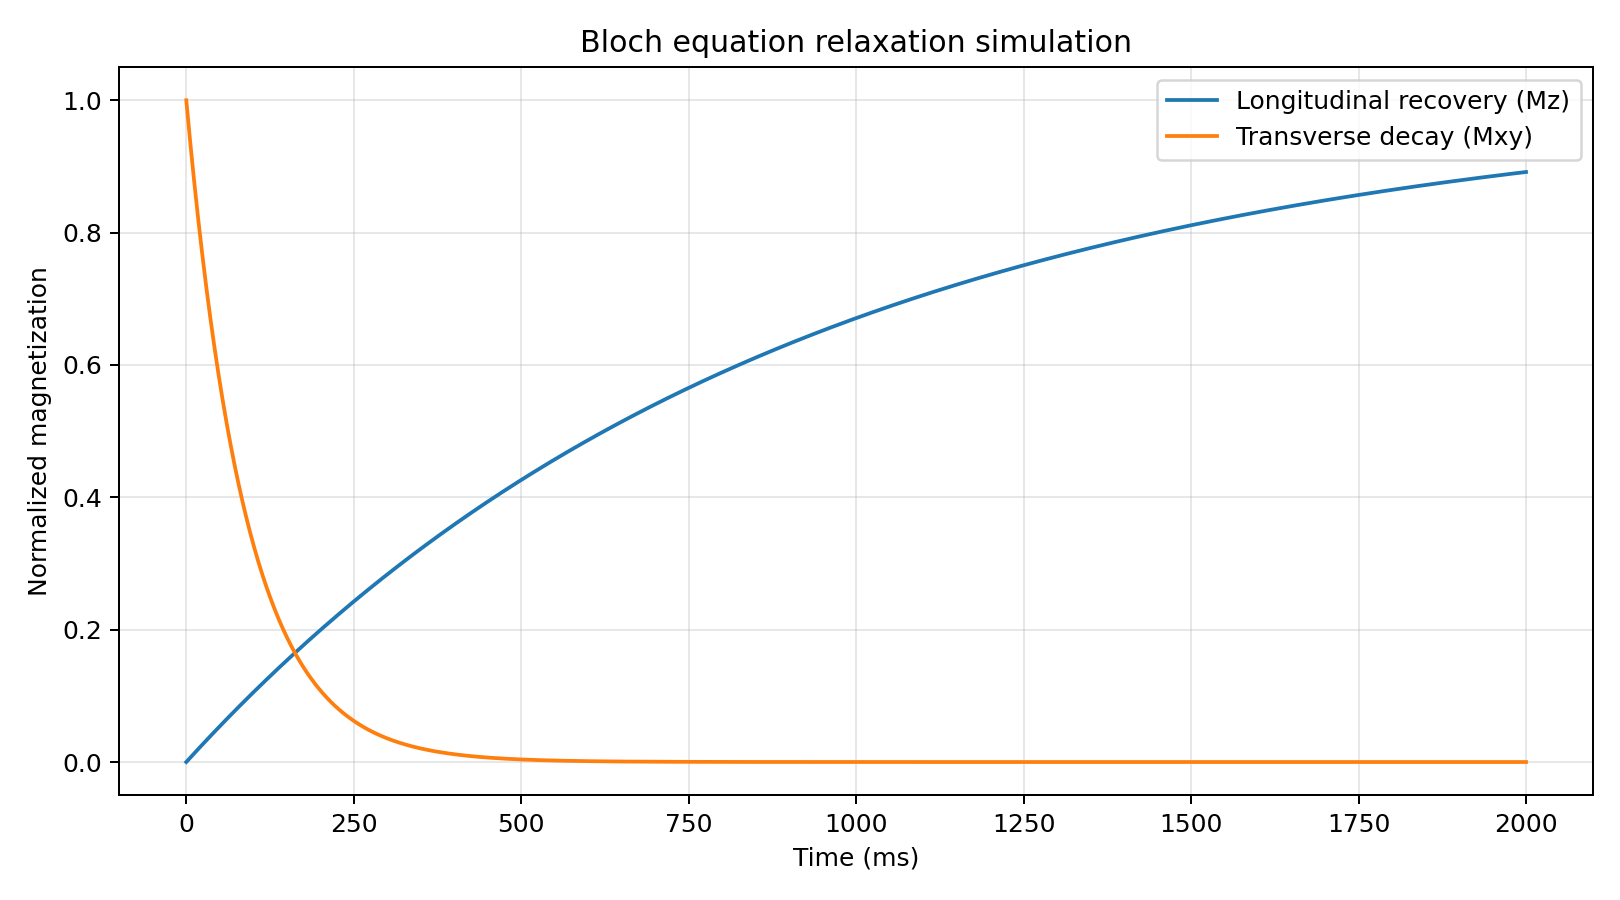

In [4]:
from IPython.display import Image, display

display(Image(
    filename="01_Bloch_Equation_Simulation/figures/relaxation.png"
))

In [6]:
# MRI relaxation parameters
T1 = 1.0
T2 = 0.1
M0 = 1.0

def bloch_relaxation(t, M):
    Mx, My, Mz = M

    dMx_dt = -Mx / T2
    dMy_dt = -My / T2
    dMz_dt = (M0 - Mz) / T1

    return [dMx_dt, dMy_dt, dMz_dt]

In [7]:
M_initial = [1.0, 0.0, 0.0]

rates = bloch_relaxation(0, M_initial)

print("dMx/dt =", rates[0])
print("dMy/dt =", rates[1])
print("dMz/dt =", rates[2])

dMx/dt = -10.0
dMy/dt = -0.0
dMz/dt = 1.0


In [8]:
import numpy as np
from scipy.integrate import solve_ivp

# Time points where we want the solution
time = np.linspace(0, 3, 300)

# Initial magnetization after an ideal 90-degree RF pulse
M_initial = [1.0, 0.0, 0.0]

# Numerically solve the Bloch relaxation equations
solution = solve_ivp(
    bloch_relaxation,
    t_span=(0, 3),
    y0=M_initial,
    t_eval=time
)

print("Solver successful:", solution.success)
print("Solution shape:", solution.y.shape)
print("Final magnetization:", solution.y[:, -1])

Solver successful: True
Solution shape: (3, 300)
Final magnetization: [3.50475256e-07 0.00000000e+00 9.50212684e-01]


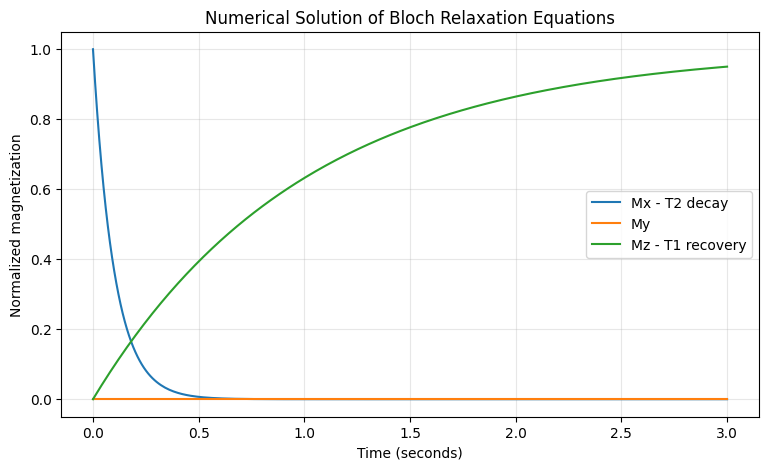

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(time, solution.y[0], label="Mx - T2 decay")
plt.plot(time, solution.y[1], label="My")
plt.plot(time, solution.y[2], label="Mz - T1 recovery")

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized magnetization")
plt.title("Numerical Solution of Bloch Relaxation Equations")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [10]:
Mx_exact = np.exp(-time / T2)
Mz_exact = M0 * (1 - np.exp(-time / T1))

error_Mx = np.max(np.abs(solution.y[0] - Mx_exact))
error_Mz = np.max(np.abs(solution.y[2] - Mz_exact))

print("Maximum absolute error in Mx:", error_Mx)
print("Maximum absolute error in Mz:", error_Mz)

Maximum absolute error in Mx: 0.0006628706445169774
Maximum absolute error in Mz: 9.019837377000073e-07


In [11]:
import numpy as np
from scipy.integrate import solve_ivp

# Gyromagnetic ratio for hydrogen (rad/s/T)
gamma = 2 * np.pi * 42.58e6

# RF pulse duration (seconds)
tau = 1e-3  # 1 millisecond

# Desired flip angle
flip_angle = np.pi / 2  # 90 degrees

# Calculate required effective RF amplitude
B1 = flip_angle / (gamma * tau)

print("RF amplitude:", B1 * 1e6, "microtesla")

# Bloch equations during RF excitation
def bloch_rf(t, M):
    Mx, My, Mz = M

    dMx = gamma * B1 * Mz
    dMy = 0.0
    dMz = -gamma * B1 * Mx

    return [dMx, dMy, dMz]

# Initial equilibrium magnetization
M_initial = [0.0, 0.0, 1.0]

# Simulate the RF pulse
time_rf = np.linspace(0, tau, 200)

solution_rf = solve_ivp(
    bloch_rf,
    (0, tau),
    M_initial,
    t_eval=time_rf,
    rtol=1e-9,
    atol=1e-11
)

print("Solver successful:", solution_rf.success)
print("Final magnetization:", solution_rf.y[:, -1])

RF amplitude: 5.871301080319399 microtesla
Solver successful: True
Final magnetization: [ 1.00000000e+00  0.00000000e+00 -2.36127298e-11]


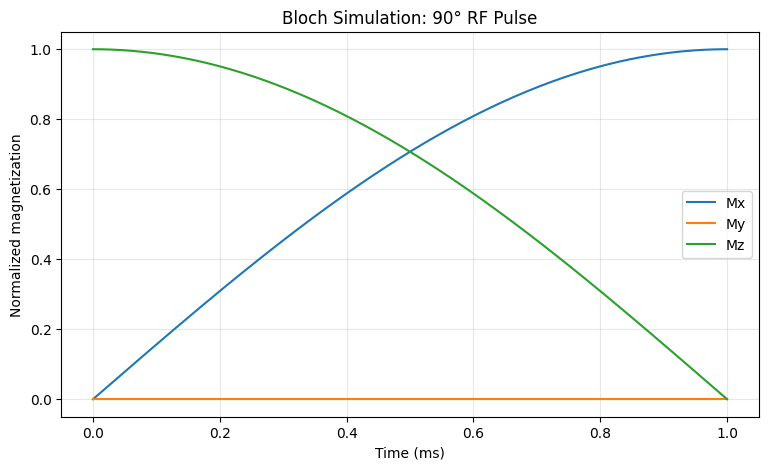

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(time_rf * 1000, solution_rf.y[0], label="Mx")
plt.plot(time_rf * 1000, solution_rf.y[1], label="My")
plt.plot(time_rf * 1000, solution_rf.y[2], label="Mz")

plt.xlabel("Time (ms)")
plt.ylabel("Normalized magnetization")
plt.title("Bloch Simulation: 90° RF Pulse")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [13]:
flip_angles = [30, 90, 180]

results = {}

for angle in flip_angles:

    alpha = np.deg2rad(angle)

    # RF amplitude needed for this flip angle
    B1 = alpha / (gamma * tau)

    # Solve the Bloch equations
    sol = solve_ivp(
        bloch_rf,
        (0, tau),
        [0.0, 0.0, 1.0],
        t_eval=time_rf,
        rtol=1e-9,
        atol=1e-11
    )

    results[angle] = sol

    print(f"\nFlip angle: {angle} degrees")
    print("Final Mx:", sol.y[0, -1])
    print("Final Mz:", sol.y[2, -1])


Flip angle: 30 degrees
Final Mx: 0.4999999999815609
Final Mz: 0.8660254037447495

Flip angle: 90 degrees
Final Mx: 0.9999999997631408
Final Mz: -2.3612729826982815e-11

Flip angle: 180 degrees
Final Mx: -4.7263587141244123e-11
Final Mz: -0.9999999995256862


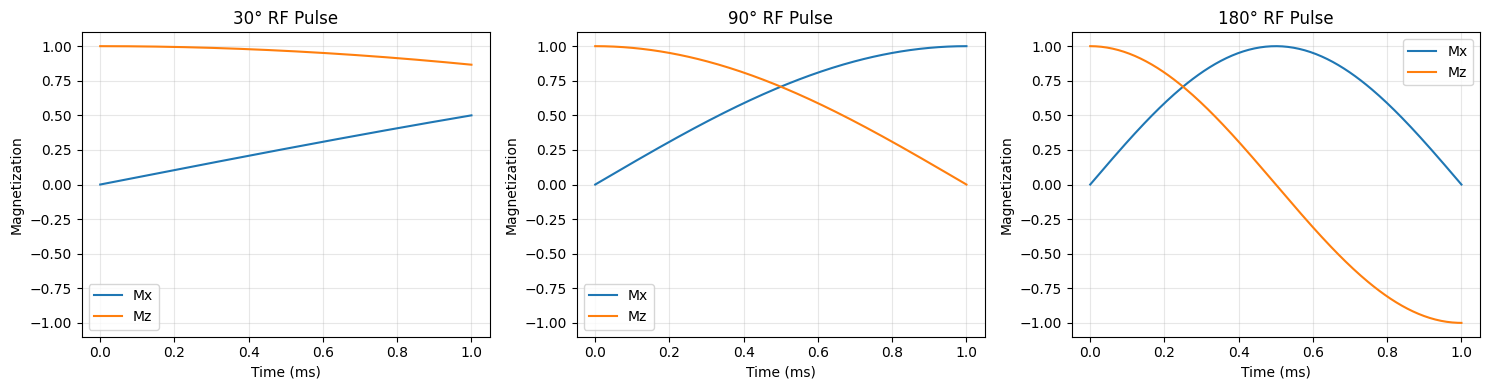

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, angle in zip(axes, flip_angles):

    sol = results[angle]

    ax.plot(time_rf * 1000, sol.y[0], label="Mx")
    ax.plot(time_rf * 1000, sol.y[2], label="Mz")

    ax.set_title(f"{angle}° RF Pulse")
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Magnetization")
    ax.set_ylim(-1.1, 1.1)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [15]:
for angle in flip_angles:

    sol = results[angle]
    alpha = np.deg2rad(angle)

    numerical = sol.y[:, -1]

    analytical = np.array([
        np.sin(alpha),
        0.0,
        np.cos(alpha)
    ])

    error = np.linalg.norm(numerical - analytical)

    print(f"{angle}° pulse | Error = {error:.2e}")

30° pulse | Error = 4.38e-11
90° pulse | Error = 2.38e-10
180° pulse | Error = 4.77e-10


In [16]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Physical parameters
gamma = 2 * np.pi * 42.58e6
T1 = 1.0
T2 = 0.1
M0 = 1.0

# RF pulse parameters
tau = 1e-3
flip_angle = np.pi / 2
B1 = flip_angle / (gamma * tau)

# Combined Bloch equations
def bloch_combined(t, M, B1_current):
    Mx, My, Mz = M

    dMx = gamma * B1_current * Mz - Mx / T2
    dMy = -My / T2
    dMz = -gamma * B1_current * Mx + (M0 - Mz) / T1

    return [dMx, dMy, dMz]

# Stage 1: Initial equilibrium
M_initial = [0.0, 0.0, 1.0]

# Stage 2: RF excitation
t_rf = np.linspace(0, tau, 200)

rf_solution = solve_ivp(
    lambda t, M: bloch_combined(t, M, B1),
    (0, tau),
    M_initial,
    t_eval=t_rf,
    rtol=1e-9,
    atol=1e-11
)

# Stage 3: Free relaxation
t_relax = np.linspace(tau, 3, 500)

relax_solution = solve_ivp(
    lambda t, M: bloch_combined(t, M, 0.0),
    (tau, 3),
    rf_solution.y[:, -1],
    t_eval=t_relax,
    rtol=1e-9,
    atol=1e-11
)

print("RF solver successful:", rf_solution.success)
print("Relaxation solver successful:", relax_solution.success)
print("Magnetization after RF:", rf_solution.y[:, -1])

RF solver successful: True
Relaxation solver successful: True
Magnetization after RF: [0.99515357 0.         0.00349267]


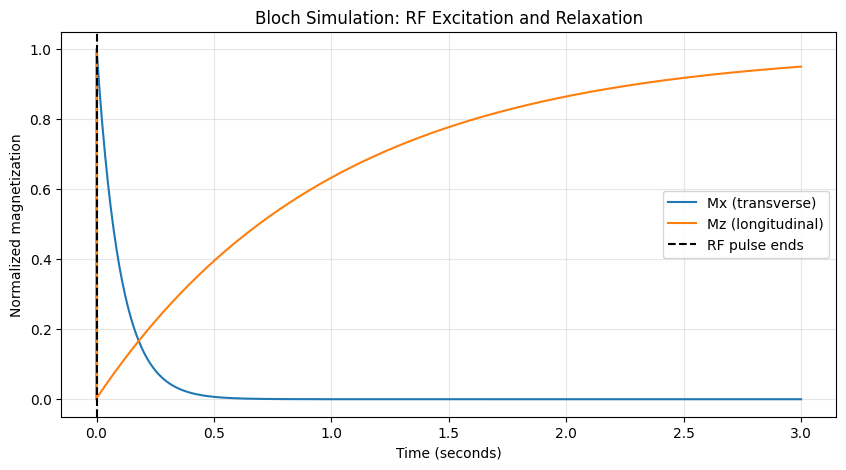

In [17]:
# Combine time points, avoiding a duplicate at the pulse boundary
time_all = np.concatenate([t_rf, t_relax[1:]])

Mx_all = np.concatenate([
    rf_solution.y[0],
    relax_solution.y[0, 1:]
])

Mz_all = np.concatenate([
    rf_solution.y[2],
    relax_solution.y[2, 1:]
])

plt.figure(figsize=(10, 5))

plt.plot(time_all, Mx_all, label="Mx (transverse)")
plt.plot(time_all, Mz_all, label="Mz (longitudinal)")

plt.axvline(
    tau,
    color="black",
    linestyle="--",
    label="RF pulse ends"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized magnetization")
plt.title("Bloch Simulation: RF Excitation and Relaxation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

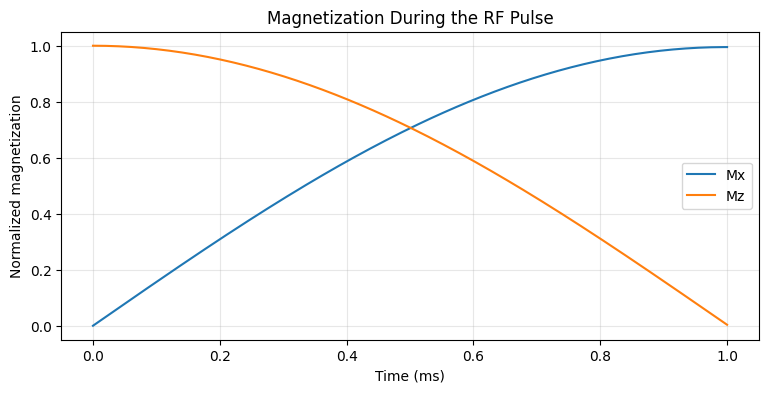

In [18]:
plt.figure(figsize=(9, 4))

plt.plot(t_rf * 1000, rf_solution.y[0], label="Mx")
plt.plot(t_rf * 1000, rf_solution.y[2], label="Mz")

plt.xlabel("Time (ms)")
plt.ylabel("Normalized magnetization")
plt.title("Magnetization During the RF Pulse")
plt.legend()
plt.grid(alpha=0.3)
plt.show()